In [1]:
import numpy as np
from scipy.ndimage import gaussian_filter, gaussian_filter, rotate, shift
from PIL import Image
import matplotlib.pyplot as plt
import cv2

In [2]:
def unsharp_masking(x, s, k):
    x = x.astype(np.float32)
    xb = gaussian_filter(x, sigma=(s,s,0))
    mask = x - xb
    x = x + k*mask
    return np.clip(x, 0, 255).astype(np.uint8)

def draw1(path, s=1, k=1):
    x = np.array(Image.open(path).convert("RGB"), dtype=float)
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 4, 1)
    plt.imshow(x.astype(np.uint8))
    plt.subplot(1, 4, 2)
    plt.imshow(unsharp_masking(x,s,k).astype(np.uint8))

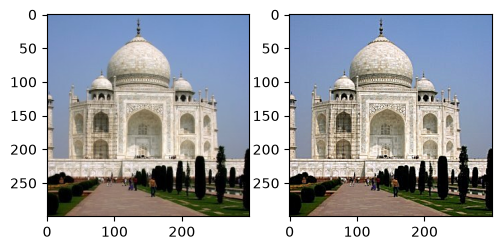

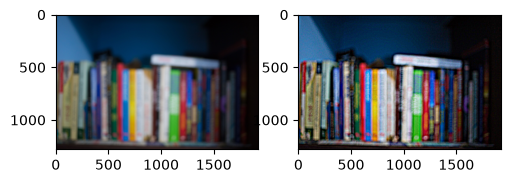

In [3]:
draw1("./images/taj.jpg", 1.5, 0.8)
draw1("./images/myblur.jpg", 9, 5)

In [4]:
def draw2(
    im1_path: str,
    im2_path: str,
    offset: tuple = (0, 0),
    angle: float = 0.0,
    scale: float = 1.0,
    cutoff_low: float = 6.0,
    cutoff_high: float = 6.0,
):
    im1 = cv2.imread(im1_path, cv2.IMREAD_GRAYSCALE)
    im2 = cv2.imread(im2_path, cv2.IMREAD_GRAYSCALE)
    im1 = im1.astype(np.float32) / 255.0
    im2 = im2.astype(np.float32) / 255.0
    if scale != 1.0:
        new_w = int(im2.shape[1] * scale)
        new_h = int(im2.shape[0] * scale)
        im2 = cv2.resize(im2, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    if angle != 0.0:
        im2 = rotate(im2, angle, reshape=False, mode='constant', cval=0.0)
    h1, w1 = im1.shape
    h2, w2 = im2.shape
    im2_aligned = np.zeros_like(im1)
    start_y = (h1 - h2) // 2
    start_x = (w1 - w2) // 2
    y1_dst = max(start_y, 0)
    y2_dst = min(start_y + h2, h1)
    x1_dst = max(start_x, 0)
    x2_dst = min(start_x + w2, w1)
    y1_src = max(-start_y, 0)
    y2_src = y1_src + (y2_dst - y1_dst)
    x1_src = max(-start_x, 0)
    x2_src = x1_src + (x2_dst - x1_dst)
    
    im2_aligned[y1_dst:y2_dst, x1_dst:x2_dst] = im2[y1_src:y2_src, x1_src:x2_src]

    dx, dy = offset
    im2_aligned = shift(im2_aligned, shift=(dy, dx), mode='constant', cval=0.0)

    low_pass = gaussian_filter(im1, sigma=cutoff_low)
    high_pass = im2_aligned - gaussian_filter(im2_aligned, sigma=cutoff_high)
    hybrid_img = np.clip((low_pass + high_pass) / 2.0 + 0.5, 0.0, 1.0)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 5, 1)
    plt.imshow(im1, cmap="gray")
    plt.subplot(1, 5, 2)
    plt.imshow(im2_aligned, cmap="gray")
    plt.subplot(1, 5, 3)
    plt.imshow(low_pass, cmap="gray")
    plt.subplot(1, 5, 4)
    plt.imshow(np.clip(high_pass + 0.5, 0.0, 1.0), cmap="gray")
    plt.subplot(1, 5, 5)
    plt.imshow(hybrid_img, cmap="gray")

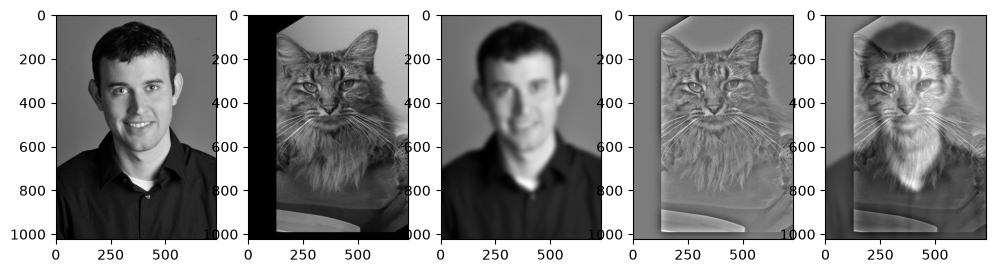

In [5]:
draw2(
    im1_path="./images/DerekPicture.jpg",
    im2_path="./images/nutmeg.jpg",
    offset=(129, -33),
    angle=32,
    cutoff_low=9,
    cutoff_high=22,
)

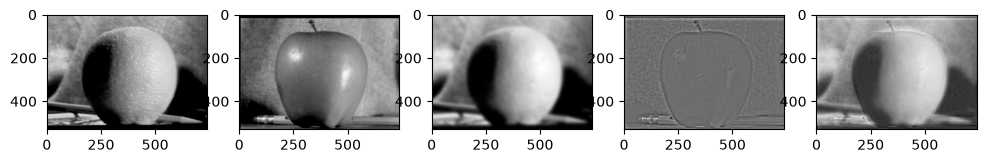

In [6]:
draw2(
    im1_path="./images/burt_orange.png",
    im2_path="./images/burt_apple.png",
    offset=(7,17),
    cutoff_low=6,
    cutoff_high=6,
)

In [7]:
def load(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (256, 256))

def gaussian_stack(img, levels, base_sigma=2.0):
    img_float = img.astype(np.float32)
    stack = [img_float]
    for i in range(1, levels):
        sigma = base_sigma * (2 ** (i - 1))
        blurred = cv2.GaussianBlur(img_float, (0, 0), sigmaX=sigma, sigmaY=sigma)
        stack.append(blurred)
    return stack

def laplacian_stack(g_stack):
    l_stack = []
    for i in range(len(g_stack) - 1):
        l_stack.append(g_stack[i] - g_stack[i + 1])
    l_stack.append(g_stack[-1])
    return l_stack

def show_norm(layer, is_laplacian=True):
    if is_laplacian:
        out = layer + 128.0
        return np.clip(out, 0, 255).astype(np.uint8)
    else:
        return np.clip(layer, 0, 255).astype(np.uint8)

def draw3():
    apple = load("./images/burt_apple.png")
    orange = load("./images/burt_orange.png")
    levels = 5
    base_sigma = 4.0
    g_apple = gaussian_stack(apple, levels, base_sigma)
    g_orange = gaussian_stack(orange, levels, base_sigma)
    l_apple = laplacian_stack(g_apple)
    l_orange = laplacian_stack(g_orange)
    mask = np.zeros((256, 256, 3), dtype=np.float32)
    mask[:, :128, :] = 1.0
    g_mask_255 = gaussian_stack(mask * 255.0, levels, base_sigma)
    g_mask = [m / 255.0 for m in g_mask_255]
    l_blend = []
    for i in range(levels):
        blend_layer = g_mask[i] * l_apple[i] + (1 - g_mask[i]) * l_orange[i]
        l_blend.append(blend_layer)
    result = np.zeros_like(l_blend[0])
    for layer in l_blend:
        result += layer
    result = np.clip(result, 0, 255).astype(np.uint8)
    fig, axes = plt.subplots(4, 3, figsize=(9, 12))

    display_indices = [0, 2, 4]

    for row, idx in enumerate(display_indices):
        is_lap = (idx != levels - 1)
        left = g_mask[idx] * l_apple[idx]
        axes[row, 0].imshow(show_norm(left, is_lap))
        mid = (1 - g_mask[idx]) * l_orange[idx]
        axes[row, 1].imshow(show_norm(mid, is_lap))
        right = l_blend[idx]
        axes[row, 2].imshow(show_norm(right, is_lap))

    smooth_mask = g_mask[2]
    axes[3, 0].imshow(np.clip(apple * smooth_mask, 0, 255).astype(np.uint8))
    axes[3, 1].imshow(np.clip(orange * (1 - smooth_mask), 0, 255).astype(np.uint8))
    axes[3, 2].imshow(result)

    plt.show()

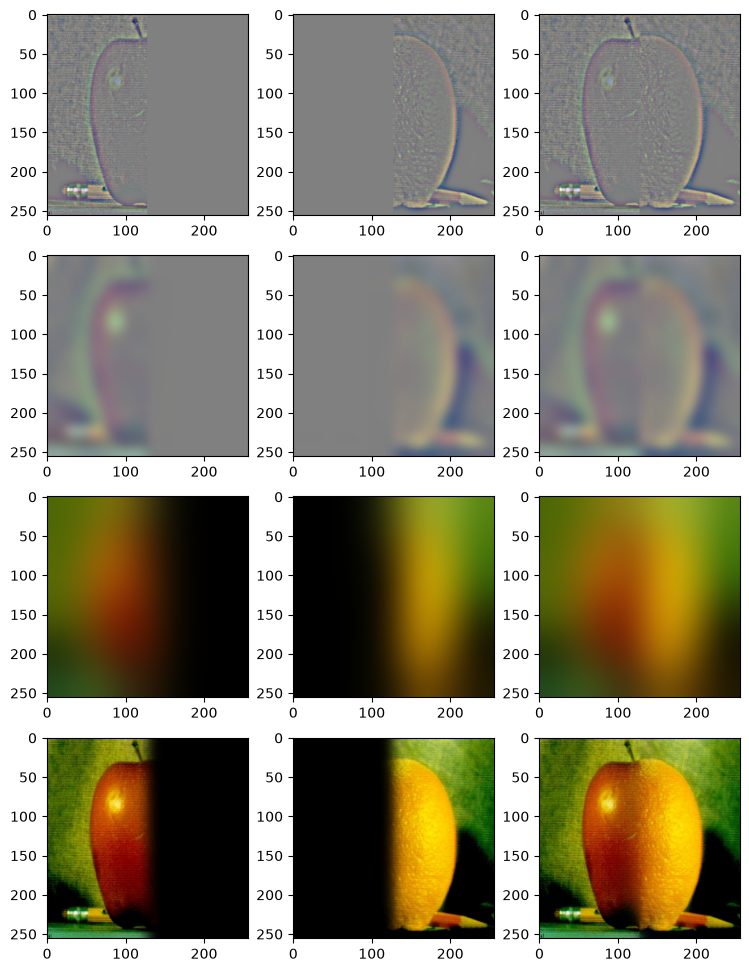

In [8]:
draw3()

In [39]:
def draw4(path_A, path_B, levels=5, base_sigma=4.0, angle=0.0, center_ratio=(0.5, 0.5)):
    imgA = load(path_A)
    imgB = load(path_B)
    
    g_stack_A = gaussian_stack(imgA, levels, base_sigma)
    g_stack_B = gaussian_stack(imgB, levels, base_sigma)
    l_stack_A = laplacian_stack(g_stack_A)
    l_stack_B = laplacian_stack(g_stack_B)
    
    h, w, c = imgA.shape
    cx, cy = w * center_ratio[0], h * center_ratio[1]
    y_coords, x_coords = np.indices((h, w))
    theta = np.deg2rad(angle)
    nx, ny = np.cos(theta), np.sin(theta)
    
    proj = (x_coords - cx) * nx + (y_coords - cy) * ny
    mask_2d = (proj <= 0).astype(np.float32)
    mask = np.repeat(mask_2d[:, :, np.newaxis], c, axis=2)
    
    g_stack_mask_255 = gaussian_stack(mask * 255.0, levels, base_sigma)
    g_stack_mask = [m / 255.0 for m in g_stack_mask_255]
    
    l_stack_blend = []
    for i in range(levels):
        blend_layer = g_stack_mask[i] * l_stack_A[i] + (1 - g_stack_mask[i]) * l_stack_B[i]
        l_stack_blend.append(blend_layer)
        
    final_blend = np.zeros_like(l_stack_blend[0])
    for layer in l_stack_blend:
        final_blend += layer
    final_blend = np.clip(final_blend, 0, 255).astype(np.uint8)

    fig, axes = plt.subplots(1, 5, figsize=(12, 8))
    
    smooth_mask = g_stack_mask[2] 
    masked_A = np.clip(imgA * smooth_mask, 0, 255).astype(np.uint8)
    masked_B = np.clip(imgB * (1 - smooth_mask), 0, 255).astype(np.uint8)


    axes[0].imshow(imgA)
    axes[1].imshow(imgB)
    axes[2].imshow(masked_A)
    axes[3].imshow(masked_B)
    axes[4].imshow(final_blend)

    plt.show()

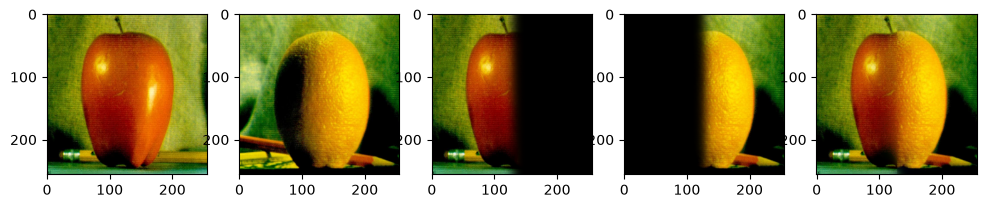

In [40]:
draw4("./images/burt_apple.png", "./images/burt_orange.png")

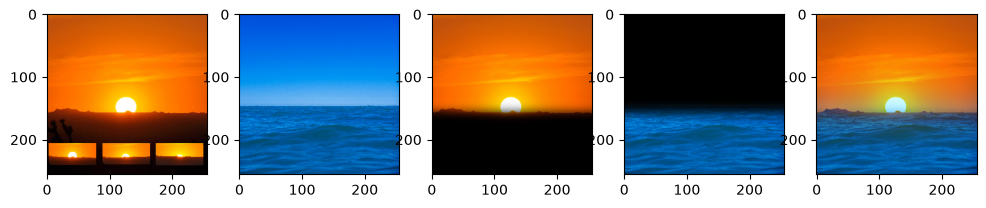

In [57]:
draw4("./images/sun.png", "./images/sea.jpg", angle=90, center_ratio=(0.5, 0.61))

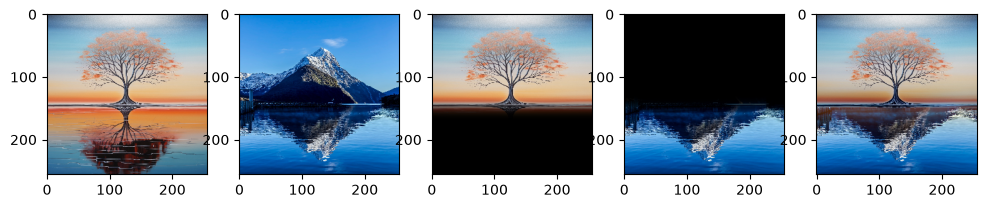

In [66]:
draw4("./images/tree.jpg", "./images/mount.jpg", angle=90, center_ratio=(0.5, 0.58))